# Ôn tập Grid-based clustering và STING

**Học máy · Nhóm 15 · Chủ đề 6**

| Thành phần | Cách hiểu |
|---|---|
| Chủ đề | Grid-based clustering, tức phân cụm dựa trên lưới. |
| Thuật toán nhóm chọn | Biến thể rút gọn của STING. |
| Dữ liệu minh họa | Ví dụ lưới 3 × 3, bộ điểm giả lập và dữ liệu thật PAPI. |

Grid-based là nhóm phương pháp. STING là một thuật toán thuộc nhóm đó. PAPI cung cấp dữ liệu để nhóm thử áp dụng thuật toán.

Bộ file để trình chiếu nằm trong [submissions/01-giua-ky](../submissions/01-giua-ky/). Câu hỏi cơ bản và kịch bản tập nói nằm trong [reports/on-tap](../reports/on-tap/).

## Ba ví dụ trong bài dùng để làm gì?

| Ví dụ | Đầu vào | Điều cần hiểu từ kết quả |
|---|---|---|
| Lưới 3 × 3 | 15 điểm được đặt vào các ô, chọn ngưỡng 3 điểm. | Hai cụm 7 điểm và một điểm nhiễu. Theo dõi cách các ô chung cạnh tạo cụm. |
| Dữ liệu giả lập | 240 điểm được sinh từ hai nhóm tham chiếu. | Dùng ARI so với nhãn đã biết để kiểm chứng cài đặt. |
| PAPI thật | Các quan sát tỉnh–năm giai đoạn 2011–2024. | Minh họa ứng dụng trên hai chỉ tiêu sau chuẩn hóa và xem độ nhạy tham số. |

Với PAPI, mỗi điểm đại diện cho một tỉnh trong một năm. Hai chỉ tiêu dùng cho phân cụm là kiểm soát tham nhũng trong cung ứng dịch vụ công và y tế công lập. STING nhận giá trị sau chuẩn hóa; đơn vị hiển thị được ghi trên trục từng hình. Biểu đồ dự đoán năm 2024 hiển thị điểm thành phần PAPI gốc để dễ diễn giải. Bảng PAPI có 41 cột, còn demo phân cụm sử dụng hai chỉ tiêu đã chọn.

## Nói với thầy thế nào ở giữa kỳ?

> Thưa thầy, nhóm em phụ trách chủ đề phân cụm dựa trên lưới và chọn biến thể rút gọn của STING. Nhóm em dùng ví dụ lưới 3 × 3 để giải thích cách đếm điểm, chọn ô dày và nối các ô thành cụm. Nhóm em cũng đã chuẩn bị dữ liệu PAPI để giới thiệu thêm phần ứng dụng.

Giữa kỳ theo slide môn học tập trung vào định nghĩa và demo cơ bản. Khi ôn, tập giải thích ví dụ nhỏ trước rồi đến phần ứng dụng PAPI. Kịch bản theo 10 slide ở [đây](../reports/on-tap/presentation-script-261116.md).

Bản nộp được tạo từ `scripts/gen_submission_demo.py`. Bản ôn tập này giữ các giải thích chi tiết và kết quả đã lưu để đọc cùng mã.

In [1]:
import ast
import os
import re
import sys
from pathlib import Path

_STING_MARKER = Path("src") / "sting.py"


def _find_repo_root() -> Path:
    seeds: list[Path] = [Path.cwd().resolve()]
    for env_key in ("STING_REPO_ROOT", "SUBMISSION_DEMO_NB_PATH", "JPY_STARTUP_PATH"):
        raw = os.environ.get(env_key)
        if not raw:
            continue
        seeds.append(
            Path(raw).resolve()
            if env_key == "STING_REPO_ROOT"
            else Path(raw).resolve().parent
        )
    try:
        from IPython import get_ipython

        ip = get_ipython()
        if ip is not None:
            for key in ("__vsc_ipynb_file__", "__file__"):
                raw = ip.user_ns.get(key)
                if raw:
                    seeds.append(Path(raw).resolve().parent)
    except ImportError:
        pass
    seen: set[Path] = set()
    for seed in seeds:
        cur = seed
        for _ in range(64):
            if cur in seen:
                break
            seen.add(cur)
            if (cur / _STING_MARKER).is_file():
                return cur
            parent = cur.parent
            if parent == cur:
                break
            cur = parent
    raise FileNotFoundError(
        "Không tìm thấy repo: không có src/sting.py khi đi lên từ cwd hoặc "
        "vị trí notebook — đặt STING_REPO_ROOT hoặc chạy từ thư mục gốc repo."
    )


ROOT = _find_repo_root()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

from sting import STING
from papi_pred_common import FEATURE_LABELS, load_config, load_panel
from fig_style import CLUSTER_COLORS, apply_style

apply_style()
print("import OK")

import OK


## 1. Lý thuyết STING

STING (Statistical Information Grid, Wang, Yang & Muntz, 1997) chia không gian
đặc trưng thành lưới từ thô đến mịn. Ở mức `l`, mỗi trục có `factor**l` đoạn.
Mỗi ô lưu số điểm, trung bình, độ lệch chuẩn, giá trị nhỏ nhất và lớn nhất.

1. Dựng lưới và đếm số điểm trong mỗi ô.
2. Chọn một mức lưới, đánh dấu ô có ít nhất `min_count` điểm.
3. Nối các ô dày chung cạnh để tạo cụm. Điểm trong ô thưa nhận nhãn `-1`.

Đây là biến thể Grid-based rút gọn. Bài gốc có thêm mô hình phân phối cho ô và
cắt tỉa khi duyệt lưới từ trên xuống. Demo gom ô ở một mức đã chọn.

## 2. Cài đặt từ đầu — lưới 3 × 3

Cùng ví dụ với slide 5. Lấy 3 điểm làm ngưỡng ô dày. Trong bảng này, hai vùng
chỉ chạm góc. Chạy ô dưới để xem kết quả khi nối các ô chung cạnh.

In [2]:
counts = np.array([[4, 3, 0], [1, 0, 4], [0, 0, 3]])
positions = [(col, 2 - row) for row in range(3) for col in range(3)]
points = np.repeat(positions, counts.ravel(), axis=0)
model = STING(n_levels=2, factor=3, min_count=3).fit(points)
labels = model.cluster(level=1, connectivity=1)

cell_counts = np.zeros_like(counts)
for (x, y), cell in model.cells_[1].items():
    cell_counts[2 - y, x] = cell.count
print("Số điểm trong từng ô:")
print(cell_counts)
assert np.array_equal(cell_counts, counts)

group_sizes = sorted(np.bincount(labels[labels >= 0]).tolist())
noise_count = int((labels == -1).sum())
assert group_sizes == [7, 7] and noise_count == 1
print(f"{model.n_clusters_} cụm, mỗi cụm {group_sizes[0]} điểm. {noise_count} điểm nhiễu.")

Số điểm trong từng ô:
[[4 3 0]
 [1 0 4]
 [0 0 3]]
2 cụm, mỗi cụm 7 điểm. 1 điểm nhiễu.


## 3. Kiểm chứng tổng hợp (ARI)

Kiểm chứng cài đặt bằng **ARI** trên dữ liệu giả lập 2 cụm tách biệt (seed cố định) — cùng gate
với `tests/test_sting.py::test_two_blobs_recovered` (ARI ≥ 0.9).

In [3]:
X_syn, y_true = make_blobs(n_samples=240, centers=[(-6, -6), (6, 6)],
                           cluster_std=0.6, random_state=42)
m_syn = STING(n_levels=3, factor=4, min_count=3).fit(X_syn)
lab_syn = m_syn.cluster(level=2, connectivity=1)
ari = adjusted_rand_score(y_true, lab_syn)
assert ari >= 0.9, f"ARI quá thấp: {ari:.3f}"
print(f"ARI = {ari:.3f} | nhiễu = {(lab_syn == -1).mean():.1%} | k = {m_syn.n_clusters_}")
print("Kiểm tra ARI ≥ 0.9: đạt.")

ARI = 0.950 | nhiễu = 2.5% | k = 2
Kiểm tra ARI ≥ 0.9: đạt.


## 4. Ứng dụng PAPI

- Panel PAPI gồm 882 quan sát tỉnh–năm và 41 cột. Giá trị `0.0` dùng để
  biểu thị ô thiếu được quy về NaN. Bước nhảy trung bình là dấu hiệu cần đối chiếu thang đo.
- Demo dùng hai chỉ tiêu `sd_4_2` và `sd_6_1` theo `models/predict_config.json`.
- Tính z-score trên dữ liệu đến 2023 và áp dụng cùng phép chuẩn hóa cho năm 2024.

In [4]:
cfg = load_config()
feats = cfg["features"]
panel = load_panel()
print("Panel:", panel.shape, "| tỉnh:", panel.province_code.nunique(),
      "| năm:", panel.year.min(), "→", panel.year.max())
assert panel.shape == (882, 41)
print("Đặc trưng đóng băng:", feats, "→", [FEATURE_LABELS[f] for f in feats])

Panel: (882, 41) | tỉnh: 63 | năm: 2011 → 2024
Đặc trưng đóng băng: ['sd_4_2', 'sd_6_1'] → ['4.2 Kiểm soát tham nhũng trong cung ứng dịch vụ công', '6.1 Y tế công lập']


### 4.1 Tiền xử lý theo Day 4 (Test → Decide)

Thứ tự giảng dạy: **Cleaning** (trùng khóa đầu tiên → thiếu → nhất quán → ngoại lai cuối cùng)
→ **Integration** (khóa nối, số dòng, xung đột, rò rỉ) → **Transformation** (chuẩn hóa).
Bảng dưới **đọc** artifact `results/preprocessing_audit.csv` (sinh bởi
`python scripts/preprocessing_audit.py`) — không tính lại panel trong notebook.

In [5]:
_prep = pd.read_csv(ROOT / "results" / "preprocessing_audit.csv")
_tbl = _prep.rename(
    columns={"stage": "Giai đoạn", "test": "Kiểm tra", "result": "Kết quả", "decision": "Quyết định"}
)[["Giai đoạn", "Kiểm tra", "Kết quả", "Quyết định"]]
with pd.option_context("display.max_colwidth", 72, "display.width", 140):
    print(_tbl.to_string(index=False))
print(f"Tổng {len(_tbl)} kiểm tra — thứ tự khớp Day 4 trong CSV.")

                              Giai đoạn                                              Kiểm tra                                                                                                                              Kết quả                                                                                                                                                                                Quyết định
           1. Cleaning — (a) trùng khóa Trùng khóa (province_code, year), dedup chạy ĐẦU TIÊN                                                                      0 dòng trùng / 882 dòng (882 khóa duy nhất); trùng toàn dòng: 0                                                                      Giữ đúng 1 dòng/khóa. Pipeline chặn cứng nếu phát hiện trùng (không tự bỏ dòng) — dedup nằm ở bước đầu của Cleaning.
        1. Cleaning — (b) giá trị thiếu  Ô thiếu trong 37 cột chỉ tiêu (8 chiều + tiểu chiều)                                             4649/32634 ô (14.2%); 4284 ô nằm NGO

In [6]:
ptr = panel[panel.year <= 2023].dropna(subset=feats)
scaler = StandardScaler().fit(ptr[feats])
Xz = scaler.transform(ptr[feats])
m_frozen = STING(n_levels=cfg["sting"]["n_levels"], factor=cfg["sting"]["factor"],
                 min_count=cfg["sting"]["min_count"]).fit(Xz)
lab = m_frozen.cluster(level=cfg["sting"]["cluster_level"],
                       connectivity=cfg["sting"]["connectivity"])
sizes = sorted([int((lab == c).sum()) for c in range(m_frozen.n_clusters_)], reverse=True)
noise = float((lab == -1).mean())
print(f"STING frozen: k={m_frozen.n_clusters_} | cỡ={sizes} | nhiễu={noise:.1%} (n={len(ptr)})")
_exp = pd.read_csv(ROOT / "results" / "metrics.csv")
_sting = _exp[(_exp.scope == "pooled 2011-2023") & (_exp.method == "STING (frozen)")].iloc[0]
_sizes_m = re.search(r"\[(\d+,\s*\d+,\s*\d+)\]", str(_sting.note))
exp_sizes = ast.literal_eval("[" + _sizes_m.group(1) + "]")
assert m_frozen.n_clusters_ == int(_sting.k)
assert sizes == exp_sizes
assert abs(noise - float(_sting.noise_ratio)) < 1e-3

STING frozen: k=3 | cỡ=[629, 16, 5] | nhiễu=19.6% (n=808)


In [7]:
saved = pd.read_csv(ROOT / "results" / "predict_all_years.csv", encoding="utf-8-sig")


complete = panel.dropna(subset=feats)
predicted = complete[["year", "province_code"]].assign(
    pred_cluster=m_frozen.predict(scaler.transform(complete[feats]))
)
merged = saved.merge(
    predicted, on=["year", "province_code"],
    suffixes=("_saved", "_refit"), validate="one_to_one",
)
n_diff = int((merged.pred_cluster_saved != merged.pred_cluster_refit).sum())
assert len(merged) == len(saved) == 869
assert n_diff == 0
print(f"Refit khớp {len(saved)}/{len(saved)} nhãn (0 lệch) — gate test_artifact_reproduction.")

Refit khớp 869/869 nhãn (0 lệch) — gate test_artifact_reproduction.


In [8]:
metrics = pd.read_csv(ROOT / "results" / "metrics.csv")
metrics_pooled = metrics[metrics.scope == "pooled 2011-2023"]
methods = ["STING (frozen)", "k-means k=2", "DBSCAN eps=0.2"]
print(metrics_pooled.loc[metrics_pooled.method.isin(methods),
                         ["method", "k", "noise_ratio", "silhouette"]].to_string(index=False))
print()


def safe_metrics(X, lab):
    mask = lab >= 0
    k = len(set(lab[mask]))
    if k < 2:
        return None, None, None
    return (silhouette_score(X[mask], lab[mask]),
            davies_bouldin_score(X[mask], lab[mask]),
            calinski_harabasz_score(X[mask], lab[mask]))


sil, db, ch = safe_metrics(Xz, lab)
sting_row = metrics_pooled[metrics_pooled.method == "STING (frozen)"].iloc[0]
assert abs(sil - sting_row.silhouette) < 1e-3
assert abs(db - sting_row.davies_bouldin) < 1e-3
assert abs(ch - sting_row.calinski_harabasz) < 1e-1

km2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Xz)
km2_row = metrics_pooled[metrics_pooled.method == "k-means k=2"].iloc[0]
assert abs(adjusted_rand_score(lab, km2.labels_) - km2_row.ari_vs_sting) < 1e-3
assert abs(silhouette_score(Xz, km2.labels_) - km2_row.silhouette) < 1e-3

db2 = DBSCAN(eps=0.2, min_samples=5).fit(Xz)
db2_row = metrics_pooled[metrics_pooled.method == "DBSCAN eps=0.2"].iloc[0]
assert abs(adjusted_rand_score(lab, db2.labels_) - db2_row.ari_vs_sting) < 1e-3
print("STING frozen + k-means k=2 + DBSCAN eps=0.2: khớp metrics.csv (đã assert).")

        method  k  noise_ratio  silhouette
STING (frozen)  3        0.196       0.361
   k-means k=2  2        0.000       0.445
DBSCAN eps=0.2  5        0.142       0.218



STING frozen + k-means k=2 + DBSCAN eps=0.2: khớp metrics.csv (đã assert).


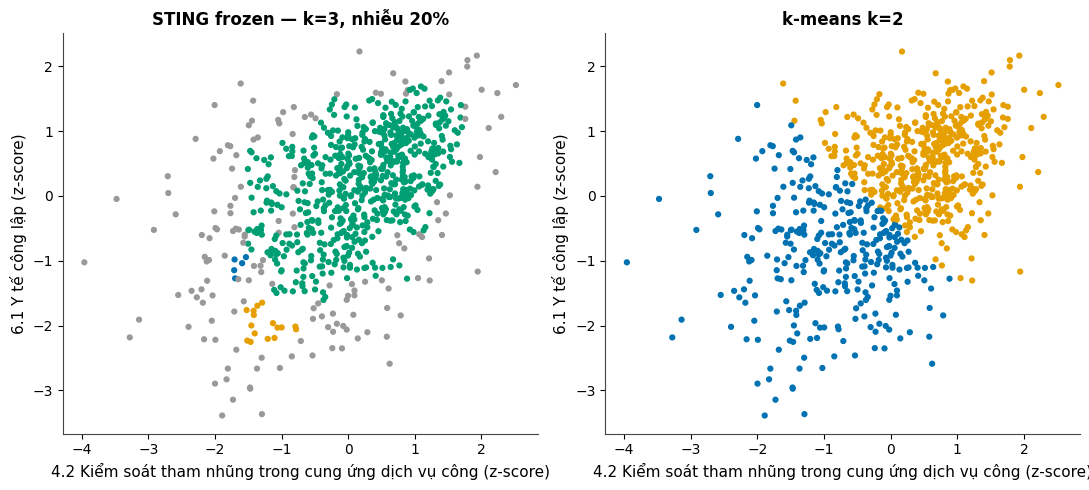

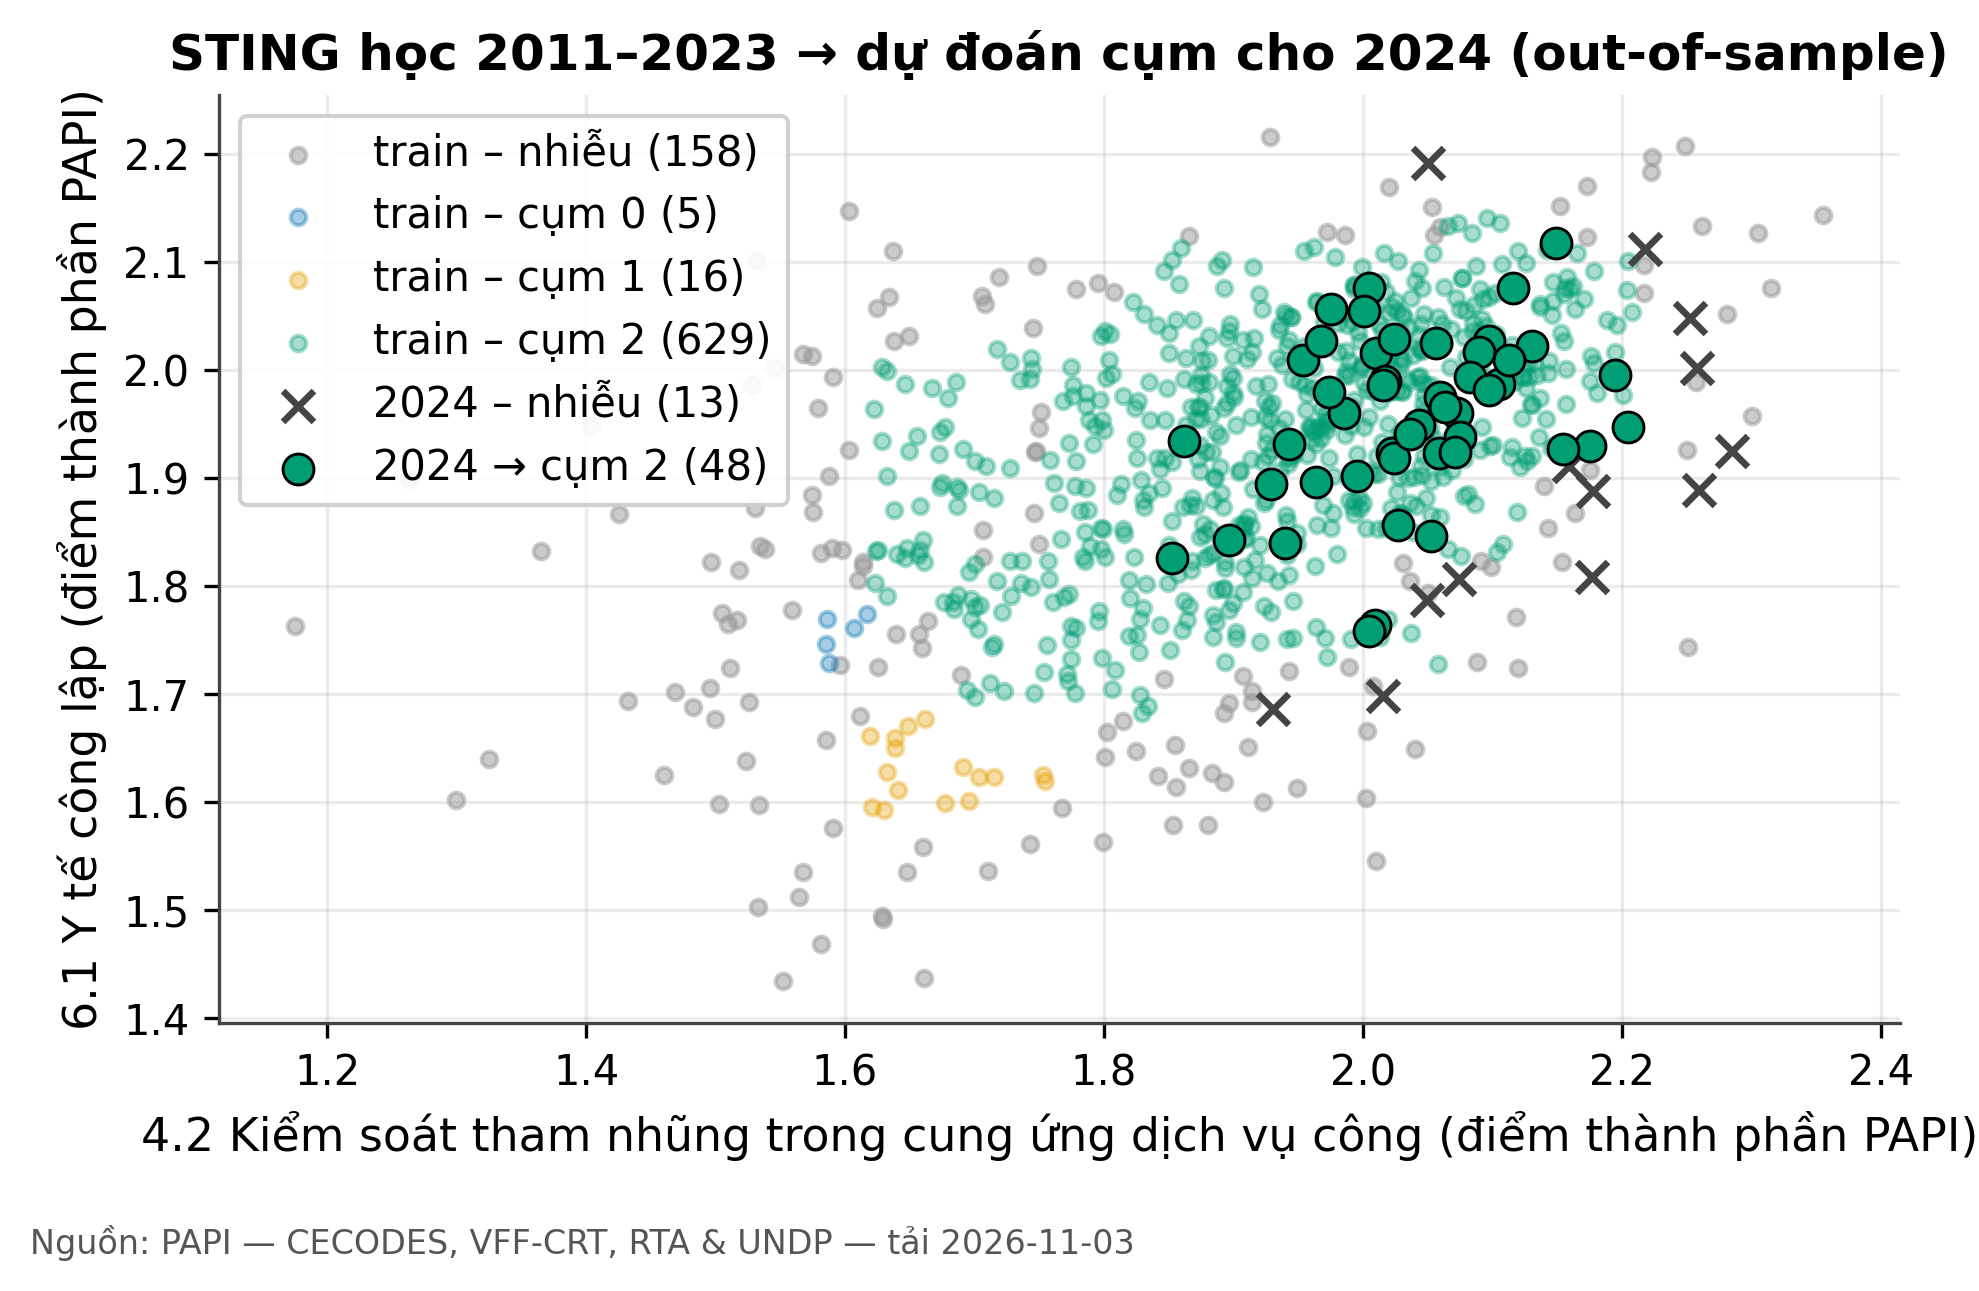

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].scatter(Xz[:, 0], Xz[:, 1], s=12, c=[CLUSTER_COLORS[int(c)] for c in lab])
axes[0].set_title(f"STING frozen — k=3, nhiễu {noise:.0%}")
axes[1].scatter(Xz[:, 0], Xz[:, 1], s=12, c=[CLUSTER_COLORS[int(c)] for c in km2.labels_])
axes[1].set_title("k-means k=2")
for ax in axes:
    ax.set_xlabel(f"{FEATURE_LABELS[feats[0]]} (z-score)")
    ax.set_ylabel(f"{FEATURE_LABELS[feats[1]]} (z-score)")
plt.tight_layout()
plt.show()

display(Image(filename=str(ROOT / "results" / "figs" / "predict_2024.png")))

In [10]:
test2024 = panel[panel.year == 2024].dropna(subset=feats)
Xte = scaler.transform(test2024[feats])
base = m_frozen.predict(Xte)
n_provinces = panel.loc[panel.year == 2024, "province_code"].nunique()
n_noise = int((base == -1).sum())
print(f"2024: {len(base)}/{n_provinces} tỉnh đủ dữ liệu, "
      f"{len(base) - n_noise} vào cụm, {n_noise} nhiễu.")

min_counts = (3, 5, 8)
sens = []
for mc in min_counts:
    mm = STING(n_levels=cfg["sting"]["n_levels"], factor=cfg["sting"]["factor"],
               min_count=mc).fit(Xz)
    mm.cluster(level=cfg["sting"]["cluster_level"], connectivity=cfg["sting"]["connectivity"])
    p = mm.predict(Xte)
    sens.append((mc, round(float((p != -1).mean()), 2), mm.n_clusters_,
                 round(float(adjusted_rand_score(p, base)), 3)))
print(f"{'min_count':>9} | {'coverage 2024':>13} | k | ARI vs chốt")
for mc, cov, k, ari in sens:
    print(f"{mc:>9} | {cov:>13.0%} | {k} | {ari:.3f}")
cov_map = {mc: round(cov, 2) for mc, cov, _, _ in sens}
ari_map = {mc: round(ari, 3) for mc, _, _, ari in sens}

def _sensitivity_expectations(md_path):
    exp = {}
    in_tbl = False
    for line in md_path.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if not line.startswith("|"):
            if in_tbl:
                break
            continue
        cols = [c.strip() for c in line.split("|")[1:-1]]
        if not in_tbl:
            in_tbl = bool(cols) and cols[0] == "min_count"
        elif len(cols) >= 4 and cols[0].isdigit():
            mc = int(cols[0])
            exp[mc] = (float(cols[1].rstrip("%")) / 100, float(cols[3]))
    if exp.keys() != set(min_counts):
        expected = ", ".join(map(str, min_counts))
        raise ValueError(f"Bảng độ nhạy cần đủ các ngưỡng {expected}. Nhận được {sorted(exp)}.")
    return exp

exp_sens = _sensitivity_expectations(ROOT / "results" / "predict_summary.md")
for mc, (ecov, eari) in exp_sens.items():
    assert abs(cov_map[mc] - round(ecov, 2)) < 1e-9
    assert ari_map[mc] == round(eari, 3)
print("Độ nhạy min_count khớp results/predict_summary.md (đã assert).")

2024: 61/63 tỉnh đủ dữ liệu, 48 vào cụm, 13 nhiễu.
min_count | coverage 2024 | k | ARI vs chốt
        3 |           82% | 3 | 0.852
        5 |           79% | 3 | 1.000
        8 |           70% | 1 | 0.678
Độ nhạy min_count khớp results/predict_summary.md (đã assert).


## 5. Kết luận và hạn chế

- Demo tổng hợp kiểm tra cách chia lưới và gom ô. ARI 0.950 đo độ khớp với nhãn tổng hợp.
- PAPI 2011–2023 có một cụm lớn và hai cụm nhỏ. Số cụm và tỷ lệ nhiễu thay đổi
  theo ngưỡng mật độ. Năm 2024 cho thấy cách gán tỉnh mới vào lưới đã học.
- Khi so sánh silhouette, đọc kèm tỷ lệ nhiễu vì mỗi phương pháp có thể được chấm
  trên tập điểm khác nhau. Các cụm mô tả hai chỉ tiêu PAPI được chọn.

**Tài liệu tham khảo:** Wang, Yang & Muntz (VLDB'97); PAPI (CECODES/VFF-CRT/RTA/UNDP);
Le et al., Mendeley Data (DOI 10.17632/wbk42j9wc8.1, CC BY 4.0).